In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import erf

In [24]:
# 读取 Excel 文件，D=刀口位置(mm)，I=功率(任意单位)
filename = "/Users/jerryling/Documents/Research/Optics_temp/976_Laesr_new.xlsx"   # 改成你的文件名
df = pd.read_excel(filename, sheet_name="exp_980_2")

# 按列名取数据（确保表头正好是 "D" 和 "I"）
D = df["D"].to_numpy(dtype=float)   # 刀口位置，单位 mm
I = df["I"].to_numpy(dtype=float)   # 透过功率

# 按位置排序，避免往返测量导致点乱序
order = np.argsort(D)
D, I = D[order], I[order]

print(f"共读取 {len(D)} 个数据点")
df.head()

共读取 16 个数据点


,D,I
0,5.00,29.4
1,0.00,23.9
2,-0.60,21.8
3,-1.24,19.3
4,-1.64,17.6


In [3]:
# 刀口法功率透过模型（高斯光束）:
#   P(x) = Pmin + (Pmax-Pmin)/2 * [1 - erf( sqrt(2)*(x - x0) / w )]
#   w 为 1/e^2 束腰半径
#
# 注意: erf 前的符号取决于刀片切入方向。
# 如果你的功率是随 D 增大而增大, 把下面的 (1 - erf) 改成 (1 + erf) 即可,
# 或者直接用绝对值 |w| 拟合, 下面用了通用写法(w可正可负, 最后取绝对值)。

def knife_edge(x, Pmin, Pmax, x0, w):
    return Pmin + (Pmax - Pmin) / 2.0 * (1.0 - erf(np.sqrt(2.0) * (x - x0) / w))

In [ ]:
# 初值估计
Pmin0 = I.min()
Pmax0 = I.max()
x0_0  = D[np.argmin(np.abs(I - (Pmax0 + Pmin0) / 2))]  # 半功率位置作为中心初值
w0    = (D.max() - D.min()) / 4.0                       # 束腰半径粗估

p0 = [Pmin0, Pmax0, x0_0, w0]

# 拟合
popt, pcov = curve_fit(knife_edge, D, I, p0=p0, maxfev=10000)
perr = np.sqrt(np.diag(pcov))   # 各参数标准误差

Pmin_fit, Pmax_fit, x0_fit, w_fit = popt
w_fit = abs(w_fit)              # 束腰半径取正
w_err = perr[3]

# 1/e^2 束腰直径 = 2 * w
diameter    = 2.0 * w_fit
diameter_err = 2.0 * w_err

print("拟合结果")
print(f"  Pmin      = {Pmin_fit:.4g} ± {perr[0]:.2g}")
print(f"  Pmax      = {Pmax_fit:.4g} ± {perr[1]:.2g}")s
print(f"  中心 x0   = {x0_fit:.4f} ± {perr[2]:.2g} mm")
print(f"  束腰半径 w = {w_fit:.4f} ± {w_err:.2g} mm")
print(f"  ---> 1/e^2 束腰直径 = {diameter:.4f} ± {diameter_err:.2g} mm")

拟合结果
  Pmin      = 29.47 ± 0.067
  Pmax      = -0.06086 ± 0.079
  中心 x0   = -2.2581 ± 0.013 mm
  束腰半径 w = 5.1297 ± 0.035 mm
  ---> 1/e^2 束腰直径 = 10.2594 ± 0.069 mm


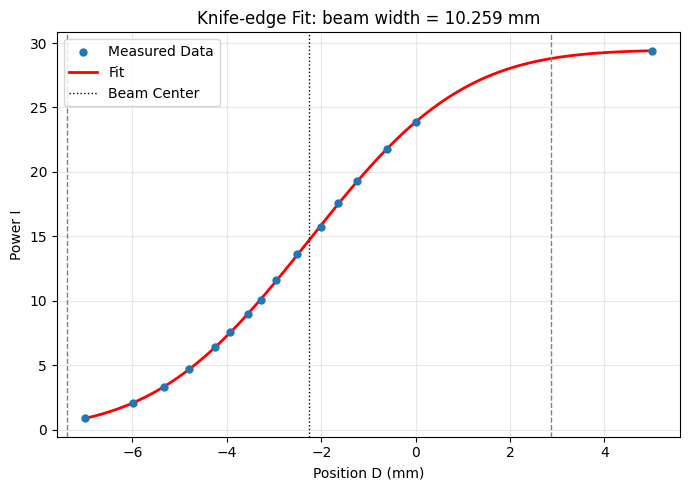

In [26]:
x_fit = np.linspace(D.min(), D.max(), 500)
y_fit = knife_edge(x_fit, *popt)

plt.figure(figsize=(7, 5))
plt.scatter(D, I, s=25, color="tab:blue", label="Measured Data", zorder=3)
plt.plot(x_fit, y_fit, "r-", lw=2, label="Fit")

# 标出束腰直径范围
plt.axvline(x0_fit - w_fit, color="gray", ls="--", lw=1)
plt.axvline(x0_fit + w_fit, color="gray", ls="--", lw=1)
plt.axvline(x0_fit, color="k", ls=":", lw=1, label="Beam Center")

plt.xlabel("Position D (mm)")
plt.ylabel("Power I")
plt.title(f"Knife-edge Fit: beam width = {diameter:.3f} mm")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()